In [14]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [11]:
class BatsmanState(TypedDict):
    runs: int
    balls : int
    fours: int
    sixes: int

    sr : float 
    bpb : float 
    boundary_percent: float 
    summary : str

In [26]:
def calculate_sr(state: BatsmanState):
    sr = (state['runs']/ state['balls'])*100
    return {'sr':sr}

In [19]:
def calculate_bpb(state: BatsmanState):
    bpb = state['balls']/ (state['fours'] + state['sixes'])
    return {'bpb':bpb}

In [20]:
def calculate_boundary_percent(state: BatsmanState):
    boundary_percent = (((state['fours']*4) + (state['sixes']*6))/state['runs'])*100
    return {'boundary_percent':boundary_percent}

In [22]:
def summary(state: BatsmanState):
    summary = f"""
Strike Rate - {state['sr']} \n
Balls per boundary - {state['bpb']} \n
Boundary Percent - {state['boundary_percent']}
"""
    return {'summary':summary }


In [27]:
graph = StateGraph(BatsmanState)

graph.add_node('calculate_sr',calculate_sr)
graph.add_node('calculate_bpb',calculate_bpb)
graph.add_node('calculate_boundary_percent',calculate_boundary_percent)
graph.add_node('generate_summary',summary)

#edges 
graph.add_edge(START, 'calculate_sr')
graph.add_edge(START, 'calculate_bpb')
graph.add_edge(START, 'calculate_boundary_percent')

graph.add_edge('calculate_sr','generate_summary')
graph.add_edge('calculate_bpb','generate_summary')
graph.add_edge('calculate_boundary_percent','generate_summary')

graph.add_edge('generate_summary', END)

workflow = graph.compile()

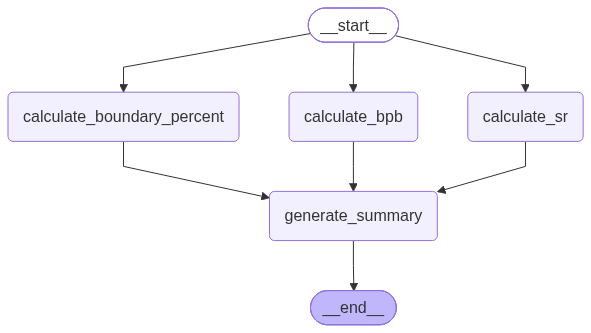

In [24]:
workflow

In [28]:
initial_state = {
    'runs': 100,
    'balls': 50,
    'fours': 6,
    'sixes': 4
}
workflow.invoke(initial_state)

{'runs': 100,
 'balls': 50,
 'fours': 6,
 'sixes': 4,
 'sr': 200.0,
 'bpb': 5.0,
 'boundary_percent': 48.0,
 'summary': '\nStrike Rate - 200.0 \n\nBalls per boundary - 5.0 \n\nBoundary Percent - 48.0\n'}